Original Dataset:
   Salary
0   25000
1   30000
2   28000
3   35000
4   40000
5   32000
6   29000
7   45000
8   50000
9  200000

IQR Outliers:
   Salary
9  200000

Z-Score Outliers:
Empty DataFrame
Columns: [Salary, Z_Score]
Index: []

Dataset After Outlier Treatment:
   Salary  Treated_Salary
0   25000           25000
1   30000           30000
2   28000           28000
3   35000           35000
4   40000           40000
5   32000           32000
6   29000           29000
7   45000           45000
8   50000           50000
9  200000           65500


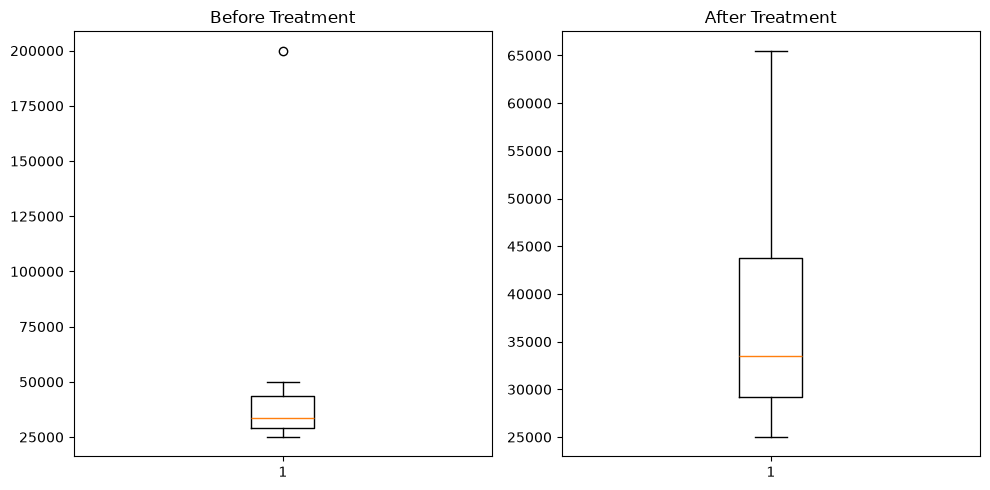

In [3]:

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create dataset
data = {
    'Salary': [25000, 30000, 28000, 35000, 40000,
               32000, 29000, 45000, 50000, 200000]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# IQR Method
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

iqr_outliers = df[
    (df['Salary'] < lower) |
    (df['Salary'] > upper)
]

print("\nIQR Outliers:")
print(iqr_outliers)

# Z-Score Method
mean = df['Salary'].mean()
std = df['Salary'].std()

df['Z_Score'] = (df['Salary'] - mean) / std

z_outliers = df[abs(df['Z_Score']) > 3]

print("\nZ-Score Outliers:")
print(z_outliers)

# Treatment using IQR (Capping)
df['Treated_Salary'] = df['Salary'].clip(
    lower=lower, upper=upper
)

print("\nDataset After Outlier Treatment:")
print(df[['Salary', 'Treated_Salary']])

# Visualization
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(df['Salary'])
plt.title("Before Treatment")

plt.subplot(1, 2, 2)
plt.boxplot(df['Treated_Salary'])
plt.title("After Treatment")

plt.tight_layout()
plt.show()
